In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from imblearn.over_sampling import RandomOverSampler, SMOTE

In [19]:
# Robust path resolution: check local data/raw, parent ../data/raw, or Colab
candidates = [
    Path("../data/raw/page-blocks0.dat"),
    Path("data/raw/page-blocks0.dat"),
    Path("/content/sample_data/page-blocks0.dat"),
]
DATA_PATH = next((p for p in candidates if p.exists()), candidates[0])

print("Dataset path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())


Dataset path: /content/sample_data/page-blocks0.dat
File exists: True


In [20]:
def load_keel(path):
    attributes = []
    data_started = False
    rows = []

    with open(path, "r") as f:
        for line in f:
            line = line.strip()

            # Ignore blank lines and comments
            if not line or line.startswith("%"):
                continue

            lower = line.lower()

            # Read attribute names
            if lower.startswith("@attribute"):
                parts = line.split()
                attributes.append(parts[1])

            # Data starts after @data
            elif lower.startswith("@data"):
                data_started = True

            # Read actual rows
            elif data_started:
                rows.append([x.strip() for x in line.split(",")])

    df = pd.DataFrame(rows, columns=attributes)

    return df

In [21]:
df = load_keel(DATA_PATH)

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
# Use IPython's built-in global display function to avoid module naming conflicts
display(df.head())

Dataset shape: (5472, 11)

First 5 rows:


,Height,Lenght,Area,Eccen,P_black,P_and,Mean_tr,Blackpix,Blackand,Wb_trans,Class
0,5,7,35,1.400,.400,.657,2.33,14,23,6,negative
1,6,7,42,1.167,.429,.881,3.60,18,37,5,negative
2,6,18,108,3.000,.287,.741,4.43,31,80,7,negative
3,5,7,35,1.400,.371,.743,4.33,13,26,3,negative
4,6,3,18.,500,.500,.944,2.25,9,17,4,negative


In [22]:
target_col = "Class"

feature_cols = [
    col for col in df.columns
    if col != target_col
]

print("Features:")
print(feature_cols)

for col in feature_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

print("\nData types:")
print(df.dtypes)

Features:
['Height', 'Lenght', 'Area', 'Eccen', 'P_black', 'P_and', 'Mean_tr', 'Blackpix', 'Blackand', 'Wb_trans']

Data types:
Height        int64
Lenght        int64
Area        float64
Eccen       float64
P_black     float64
P_and       float64
Mean_tr     float64
Blackpix      int64
Blackand      int64
Wb_trans      int64
Class        object
dtype: object


In [23]:
print("Missing values in each column:\n")
print(df.isnull().sum())

Missing values in each column:

Height      0
Lenght      0
Area        0
Eccen       0
P_black     0
P_and       0
Mean_tr     0
Blackpix    0
Blackand    0
Wb_trans    0
Class       0
dtype: int64


In [24]:
class_percentages = (
    df[target_col]
    .value_counts(normalize=True)
    * 100
)

print("\nClass percentages:")
print(class_percentages)


Class percentages:
Class
negative    89.784357
positive    10.215643
Name: proportion, dtype: float64


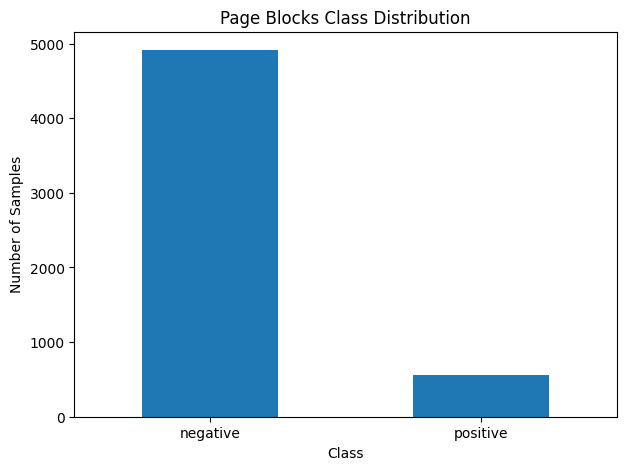

In [26]:
# Define class_counts to fix the NameError
class_counts = df[target_col].value_counts()

class_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Page Blocks Class Distribution")
plt.xticks(rotation=0)
plt.show()

In [27]:
majority_class = class_counts.idxmax()
minority_class = class_counts.idxmin()

majority_count = class_counts.max()
minority_count = class_counts.min()

IR = majority_count / minority_count

print("Majority class :", majority_class)
print("Majority count :", majority_count)

print("\nMinority class :", minority_class)
print("Minority count :", minority_count)

print("\nImbalance Ratio:", IR)

Majority class : negative
Majority count : 4913

Minority class : positive
Minority count : 559

Imbalance Ratio: 8.788908765652952


In [28]:
display(df[feature_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Height,5472.0,10.473684,18.962267,1.000,7.000,8.000,10.00000,804.0
Lenght,5472.0,89.584430,114.725992,1.000,17.000,41.000,107.00000,553.0
Area,5472.0,1198.623173,4849.793411,7.000,114.000,322.000,980.00000,143993.0
Eccen,5472.0,13.847751,31.401163,0.007,2.161,5.167,13.62500,537.0
P_black,5472.0,0.368527,0.177568,0.052,0.261,0.337,0.42525,1.0
P_and,5472.0,0.785013,0.170652,0.062,0.679,0.803,0.92700,1.0
Mean_tr,5472.0,6.218953,69.085329,1.000,1.610,2.070,3.00000,4955.0
Blackpix,5472.0,365.993238,1270.440778,1.000,42.000,108.000,284.00000,33017.0
Blackand,5472.0,741.370066,1881.626046,7.000,95.000,250.000,718.00000,46133.0
Wb_trans,5472.0,106.682200,167.317552,1.000,17.000,49.000,126.00000,3212.0


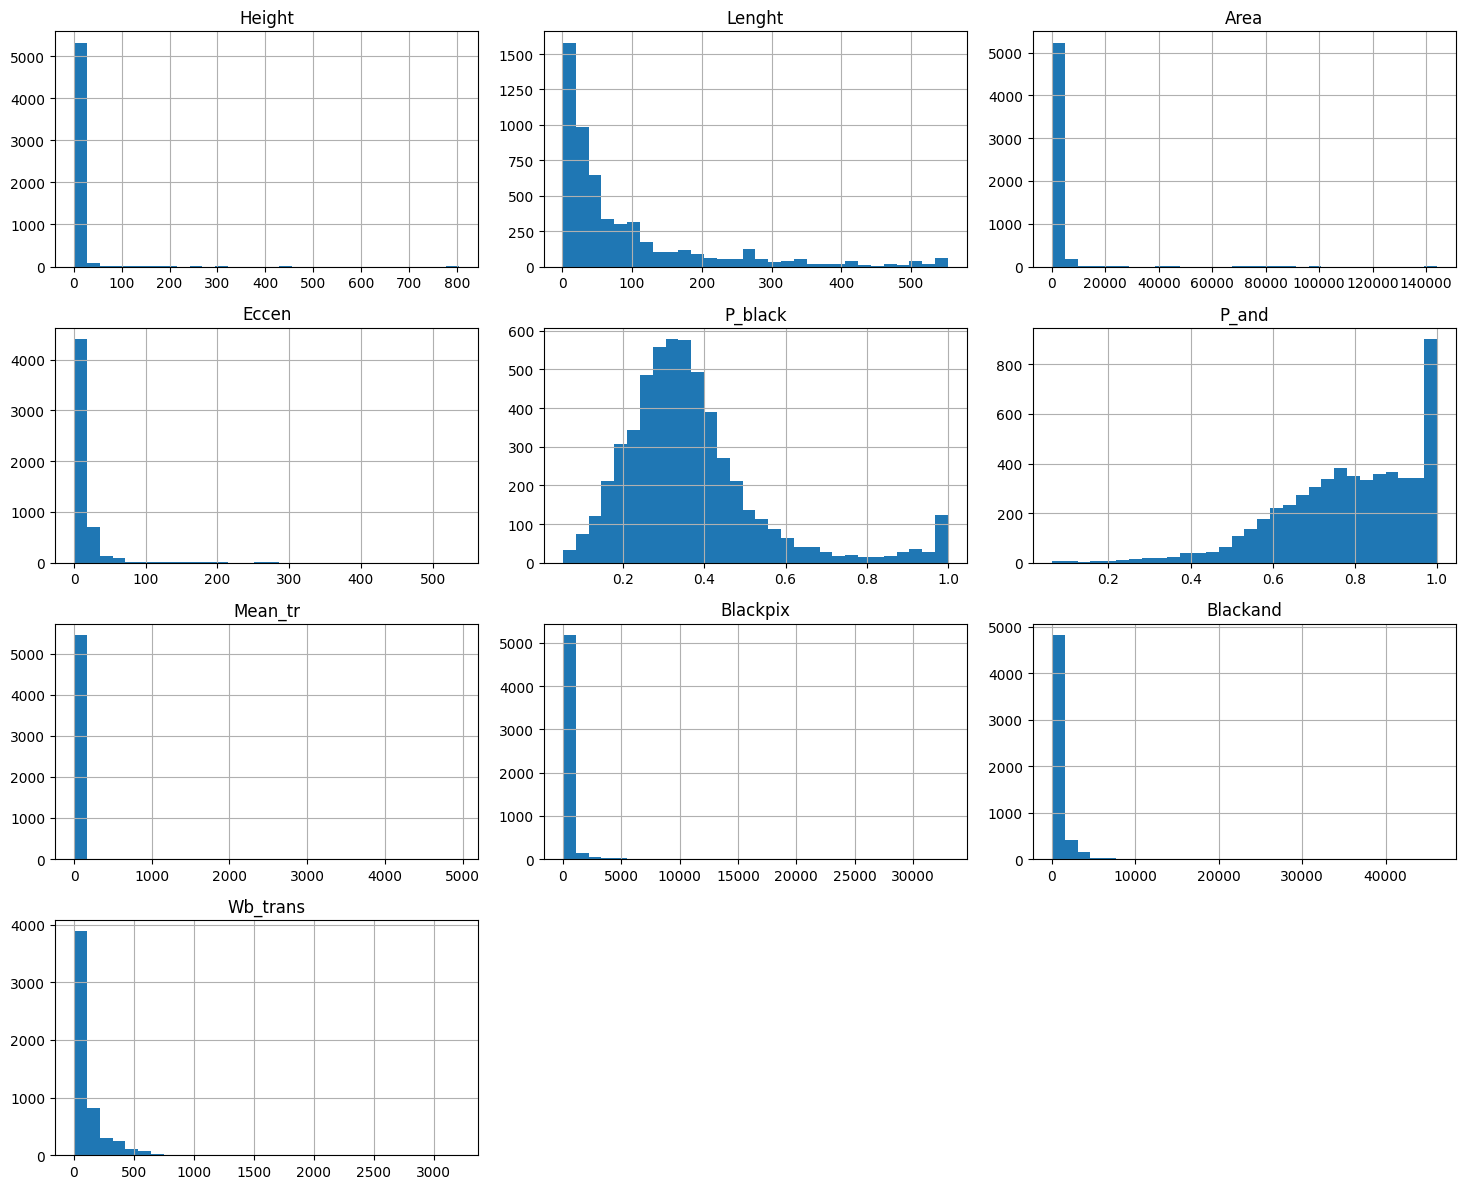

In [29]:
df[feature_cols].hist(
    figsize=(15, 12),
    bins=30
)

plt.tight_layout()
plt.show()

In [30]:
X = df[feature_cols].copy()
y = df[target_col].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5472, 10)
y shape: (5472,)


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training data:", X_train.shape)
print("Test data    :", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Training data: (4377, 10)
Test data    : (1095, 10)

Training class distribution:
Class
negative    3930
positive     447
Name: count, dtype: int64

Test class distribution:
Class
negative    983
positive    112
Name: count, dtype: int64


In [32]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=feature_cols,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=feature_cols,
    index=X_test.index
)

print("Scaled training data:")
display(X_train_scaled.head())

Scaled training data:


,Height,Lenght,Area,Eccen,P_black,P_and,Mean_tr,Blackpix,Blackand,Wb_trans
4757,5.330361,0.238518,2.379181,-0.402327,0.207367,-2.189464,1.290290,2.967253,1.856333,-0.426963
4694,-0.016738,-0.281241,-0.151261,-0.258078,0.213039,-0.281868,-0.043140,-0.106973,-0.171078,-0.170632
2391,-0.294509,-0.642430,-0.277226,-0.358263,0.683835,0.893400,-0.053598,-0.254274,-0.348940,-0.535903
2911,-0.641724,-0.721715,-0.300877,-0.215137,3.576679,1.259564,0.009930,-0.286123,-0.393540,-0.670477
5145,-0.363952,-0.730525,-0.294765,-0.406721,0.173333,0.474083,-0.055428,-0.282142,-0.383330,-0.638435


In [33]:
def evaluate_model(
    y_true,
    y_pred,
    minority_class,
    majority_class
):
    precision = precision_score(
        y_true,
        y_pred,
        pos_label=minority_class,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        pos_label=minority_class,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        pos_label=minority_class,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[majority_class, minority_class]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    gmean = np.sqrt(
        recall * specificity
    )

    return {
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Specificity": specificity,
        "G-Mean": gmean
    }

In [34]:
results = []

In [35]:
clf_original = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

clf_original.fit(
    X_train,
    y_train
)

y_pred_original = clf_original.predict(
    X_test
)

metrics_original = evaluate_model(
    y_test,
    y_pred_original,
    minority_class,
    majority_class
)

print("Original Dataset Results:")
for metric, value in metrics_original.items():
    print(f"{metric:12s}: {value:.4f}")

Original Dataset Results:
Precision   : 0.9099
Recall      : 0.9018
F1          : 0.9058
Specificity : 0.9898
G-Mean      : 0.9448


In [36]:
results.append({
    "Dataset": "page-blocks0",
    "Method": "Original",
    **metrics_original
})

In [37]:
ros = RandomOverSampler(
    random_state=42
)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train,
    y_train
)

print("Random Oversampling")
print("=" * 40)

print("\nBefore:")
print(y_train.value_counts())

print("\nAfter:")
print(y_train_ros.value_counts())

print("\nOriginal number of training rows:",
      len(X_train))

print("After Random Oversampling:",
      len(X_train_ros))

print("Number of additional rows:",
      len(X_train_ros) - len(X_train))

Random Oversampling

Before:
Class
negative    3930
positive     447
Name: count, dtype: int64

After:
Class
negative    3930
positive    3930
Name: count, dtype: int64

Original number of training rows: 4377
After Random Oversampling: 7860
Number of additional rows: 3483


In [38]:
ros_data = X_train_ros.copy()
ros_data["Class"] = y_train_ros.values

In [39]:
print("Some minority samples after Random Oversampling:")

display(
    ros_data[
        ros_data["Class"] == minority_class
    ].tail(20)
)

Some minority samples after Random Oversampling:


,Height,Lenght,Area,Eccen,P_black,P_and,Mean_tr,Blackpix,Blackand,Wb_trans,Class
7840,1,52,52.0,52.000,0.981,1.000,51.00,51,52,1,positive
7841,13,13,169.0,1.000,0.124,0.450,3.50,21,76,6,positive
7842,29,31,899.0,1.069,0.463,0.726,6.93,416,653,60,positive
7843,9,1,9.0,0.111,1.000,1.000,9.00,9,9,1,positive
7844,37,20,740.0,0.541,0.131,0.193,4.22,97,143,23,positive
7845,7,11,77.0,1.571,0.117,0.494,1.80,9,38,5,positive
7846,9,1,9.0,0.111,1.000,1.000,9.00,9,9,1,positive
7847,1,20,20.0,20.000,0.550,1.000,1.38,11,20,8,positive
7848,95,93,8835.0,0.979,0.675,0.902,3.63,5966,7968,1644,positive
7849,7,11,77.0,1.571,0.117,0.494,1.80,9,38,5,positive


In [40]:
duplicate_mask = ros_data.duplicated(
    subset=feature_cols + ["Class"]
)

print("Total rows:", len(ros_data))
print("Duplicate rows:", duplicate_mask.sum())

Total rows: 7860
Duplicate rows: 3530


In [41]:
print("Example duplicated rows:")

display(
    ros_data[duplicate_mask].head(20)
)

Example duplicated rows:


,Height,Lenght,Area,Eccen,P_black,P_and,Mean_tr,Blackpix,Blackand,Wb_trans,Class
582,9,1,9.0,0.111,1.000,1.000,9.00,9,9,1,positive
634,11,1,11.0,0.091,1.000,1.000,11.00,11,11,1,positive
975,3,3,9.0,1.000,0.889,0.889,8.00,8,8,1,negative
1151,10,1,10.0,0.100,1.000,1.000,10.00,10,10,1,positive
1467,9,1,9.0,0.111,1.000,1.000,9.00,9,9,1,positive
1608,13,1,13.0,0.077,1.000,1.000,13.00,13,13,1,positive
1624,1,8,8.0,8.000,1.000,1.000,8.00,8,8,1,positive
1714,8,1,8.0,0.125,0.875,1.000,7.00,7,8,1,positive
2002,3,3,9.0,1.000,0.778,0.778,7.00,7,7,1,negative
2016,5,7,35.0,1.400,0.400,0.657,2.33,14,23,6,negative


In [42]:
clf_ros = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

clf_ros.fit(
    X_train_ros,
    y_train_ros
)

y_pred_ros = clf_ros.predict(
    X_test
)

In [43]:
metrics_ros = evaluate_model(
    y_test,
    y_pred_ros,
    minority_class,
    majority_class
)

print("Random Oversampling Results:")
for metric, value in metrics_ros.items():
    print(f"{metric:12s}: {value:.4f}")

Random Oversampling Results:
Precision   : 0.8750
Recall      : 0.9375
F1          : 0.9052
Specificity : 0.9847
G-Mean      : 0.9608


In [44]:
results.append({
    "Dataset": "page-blocks0",
    "Method": "Random Oversampling",
    **metrics_ros
})

In [45]:
smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("SMOTE")
print("=" * 40)

print("\nBefore:")
print(y_train.value_counts())

print("\nAfter:")
print(y_train_smote.value_counts())

print("\nOriginal number of training rows:",
      len(X_train))

print("After SMOTE:",
      len(X_train_smote))

print("Number of additional rows:",
      len(X_train_smote) - len(X_train))

SMOTE

Before:
Class
negative    3930
positive     447
Name: count, dtype: int64

After:
Class
negative    3930
positive    3930
Name: count, dtype: int64

Original number of training rows: 4377
After SMOTE: 7860
Number of additional rows: 3483


In [46]:
original_train = X_train.copy()

# Convert rows into tuples for comparison
original_rows = set(
    map(tuple, original_train.to_numpy())
)

synthetic_mask = [
    tuple(row) not in original_rows
    for row in X_train_smote.to_numpy()
]

synthetic_X = X_train_smote[
    synthetic_mask
].copy()

synthetic_y = y_train_smote[
    synthetic_mask
].copy()

print("Original training rows:",
      len(X_train))

print("Total SMOTE rows:",
      len(X_train_smote))

print("Detected new rows:",
      len(synthetic_X))

Original training rows: 4377
Total SMOTE rows: 7860
Detected new rows: 3330


In [47]:
synthetic_data = synthetic_X.copy()
synthetic_data["Class"] = synthetic_y.values

print("SMOTE-generated samples:")
display(
    synthetic_data.head(20)
)

SMOTE-generated samples:


,Height,Lenght,Area,Eccen,P_black,P_and,Mean_tr,Blackpix,Blackand,Wb_trans,Class
4377,53,337,10829.645848,12.853733,0.775172,0.916645,24.144684,8539,9943,837,positive
4378,16,119,1655.668991,9.354135,0.097690,0.165462,20.887464,160,264,12,positive
4379,7,46,322.828363,6.587922,0.174752,0.302225,7.860723,56,97,7,positive
4380,1,149,149.336449,149.336449,0.984664,1.000000,73.546729,147,149,2,positive
4381,2,17,42.730721,7.668454,0.344949,0.975155,4.656648,14,41,3,positive
4382,28,32,914.628602,1.119714,0.481014,0.729611,7.166429,439,667,61,positive
4383,10,11,118.105359,1.130727,0.201606,0.605025,1.598951,23,71,15,positive
4384,21,1,21.059472,0.047881,1.000000,1.000000,21.059472,21,21,1,positive
4385,22,1,22.311002,0.044378,1.000000,1.000000,22.311002,22,22,1,positive
4386,1,14,14.000000,14.000000,0.940852,1.000000,13.166931,13,14,1,positive


In [48]:
print("Original minority samples:")

display(
    X_train[
        y_train == minority_class
    ].head(10)
)

print("\nSMOTE-generated minority samples:")

display(
    synthetic_data[
        synthetic_data["Class"] == minority_class
    ].head(10)
)

Original minority samples:


,Height,Lenght,Area,Eccen,P_black,P_and,Mean_tr,Blackpix,Blackand,Wb_trans
787,12,2,24.0,0.167,0.625,0.667,15.00,15,16,1
219,1,45,45.0,45.000,0.756,1.000,5.67,34,45,6
738,1,39,39.0,39.000,0.897,1.000,8.75,35,39,4
5212,1,235,235.0,235.000,0.923,1.000,27.13,217,235,8
4573,72,96,6912.0,1.333,0.488,0.582,15.69,3374,4025,215
3973,2,538,1076.0,269.000,0.518,0.596,29.32,557,641,19
462,12,146,1752.0,12.167,0.091,0.128,26.67,160,225,6
5277,118,105,12390.0,0.890,0.052,0.105,3.33,642,1296,193
493,212,464,98368.0,2.189,0.052,0.070,11.84,5066,6884,428
3873,3,538,1614.0,179.330,0.370,0.424,22.11,597,685,27



SMOTE-generated minority samples:


,Height,Lenght,Area,Eccen,P_black,P_and,Mean_tr,Blackpix,Blackand,Wb_trans,Class
4377,53,337,10829.645848,12.853733,0.775172,0.916645,24.144684,8539,9943,837,positive
4378,16,119,1655.668991,9.354135,0.097690,0.165462,20.887464,160,264,12,positive
4379,7,46,322.828363,6.587922,0.174752,0.302225,7.860723,56,97,7,positive
4380,1,149,149.336449,149.336449,0.984664,1.000000,73.546729,147,149,2,positive
4381,2,17,42.730721,7.668454,0.344949,0.975155,4.656648,14,41,3,positive
4382,28,32,914.628602,1.119714,0.481014,0.729611,7.166429,439,667,61,positive
4383,10,11,118.105359,1.130727,0.201606,0.605025,1.598951,23,71,15,positive
4384,21,1,21.059472,0.047881,1.000000,1.000000,21.059472,21,21,1,positive
4385,22,1,22.311002,0.044378,1.000000,1.000000,22.311002,22,22,1,positive
4386,1,14,14.000000,14.000000,0.940852,1.000000,13.166931,13,14,1,positive


In [49]:
clf_smote = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

clf_smote.fit(
    X_train_smote,
    y_train_smote
)

y_pred_smote = clf_smote.predict(
    X_test
)

In [50]:
metrics_smote = evaluate_model(
    y_test,
    y_pred_smote,
    minority_class,
    majority_class
)

print("SMOTE Results:")
for metric, value in metrics_smote.items():
    print(f"{metric:12s}: {value:.4f}")

SMOTE Results:
Precision   : 0.8120
Recall      : 0.9643
F1          : 0.8816
Specificity : 0.9746
G-Mean      : 0.9694


In [51]:
results.append({
    "Dataset": "page-blocks0",
    "Method": "SMOTE",
    **metrics_smote
})

In [52]:
results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "Specificity": "{:.4f}",
        "G-Mean": "{:.4f}"
    })
)

,Dataset,Method,Precision,Recall,F1,Specificity,G-Mean
0,page-blocks0,Original,0.9099,0.9018,0.9058,0.9898,0.9448
1,page-blocks0,Random Oversampling,0.8750,0.9375,0.9052,0.9847,0.9608
2,page-blocks0,SMOTE,0.8120,0.9643,0.8816,0.9746,0.9694


In [53]:
RESULTS_PATH = Path("../results/tables")

RESULTS_PATH.mkdir(
    parents=True,
    exist_ok=True
)

results_df.to_csv(
    RESULTS_PATH / "baseline_results_page_blocks0.csv",
    index=False
)

print(
    "Results saved to:",
    RESULTS_PATH / "baseline_results_page_blocks0.csv"
)

Results saved to: ../results/tables/baseline_results_page_blocks0.csv
